# QUOPS capability, one calculation at a time

This notebook follows single QUOPS widths through the direct and surface-code models, computes each number by hand, and checks it against the `capability` package. It then builds the capability curves for one hardware class and changes one modeling choice. The definitions are those of the methods note, `docs/quops_direct_and_surface.md`, and every choice is set in `capability/config.py`. The scripts in `scripts/` repeat sections 5 and 6 for all hardware classes and all choices. The notebook runs in about a minute.

In [1]:
import sys
from math import ceil, exp, log, log1p
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
while not (ROOT/'capability').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from capability import curves, direct, quops, routing, surface
from capability.config import BASELINE, HARDWARE, N_MAX, vary
from capability.factories import FACTORIES

PASS = exp(-BASELINE.threshold)        # a width passes if the mean no-fault probability is at least 1/sqrt(e)
for key, hw in HARDWARE.items():
    print(f'{key}  {hw.name:20s} eps_1q = {hw.eps_1q:g}, eps_2q = {hw.eps_2q:g}')
print(f'pass threshold {PASS:.4f}')

H1  2D grid, uniform     eps_1q = 0.001, eps_2q = 0.001
H2  all-to-all, uniform  eps_1q = 0.001, eps_2q = 0.001
H3  2D grid, bimodal     eps_1q = 1e-06, eps_2q = 0.001
H4  all-to-all, bimodal  eps_1q = 1e-06, eps_2q = 0.001
pass threshold 0.6065


## 1. The QUOPS problem

A QUOPS circuit on an even number $w$ of qubits alternates rotation layers, an independent $R_P(\theta)$ on every qubit with $P$ uniform in $\{X, Y, Z\}$, and CNOT layers, an independent random pairing of the qubits. Every layer has size $w$. The shallow ensemble has $w$ layers and size $s = w^2$, and the deep ensemble has $w^2$ layers and size $s = w^3$. We start with a rotation layer, so $L$ layers give $L_R = \lceil L/2\rceil$ rotation layers and $L_C = \lfloor L/2\rfloor$ CNOT layers.

In [2]:
for w in (6, 12, 16):
    for ens in quops.ENSEMBLES:
        n_rot, n_cnot = quops.layer_counts(w, ens)
        print(f'w = {w:2d}, {ens:7s}: {quops.layers(w, ens):3d} layers ({n_rot} rotation, {n_cnot} CNOT), '
              f's = {quops.size(w, ens):,}')

w =  6, shallow:   6 layers (3 rotation, 3 CNOT), s = 36
w =  6, deep   :  36 layers (18 rotation, 18 CNOT), s = 216
w = 12, shallow:  12 layers (6 rotation, 6 CNOT), s = 144
w = 12, deep   : 144 layers (72 rotation, 72 CNOT), s = 1,728
w = 16, shallow:  16 layers (8 rotation, 8 CNOT), s = 256
w = 16, deep   : 256 layers (128 rotation, 128 CNOT), s = 4,096


## 2. Direct implementation on all-to-all hardware

Every native operation takes one time step and every location fails independently, so the no-fault probability of a circuit is the product of $1 - p_\ell$ over its locations. Preparation and measurement are $2w$ locations at $\varepsilon_{2Q}$. A CNOT layer on all-to-all hardware is $w/2$ CNOTs in one step, with every qubit busy. A rotation layer lasts as long as its slowest qubit, $D = 1$, 3, or 5 steps for $R_Z$, $R_X$, and $R_Y$ compiled into $H$ and $Z(\theta)$, and every qubit is a location at $\varepsilon_{1Q}$ in each of those steps, as a gate or as an idle. The average over the ensemble is

$$
\overline q = (1-\varepsilon_{2Q})^{2w + w L_C/2}\,\Big[\sum_{D} \Pr(D)\,(1-\varepsilon_{1Q})^{wD}\Big]^{L_R},
$$

where $\Pr(D=5) = 1-(2/3)^w$, $\Pr(D=3) = (2/3)^w-(1/3)^w$, and $\Pr(D=1) = (1/3)^w$.

In [3]:
def direct_all_to_all(w, ensemble, hw):
    n_rot, n_cnot = quops.layer_counts(w, ensemble)
    pD = {5: 1 - (2/3)**w, 3: (2/3)**w - (1/3)**w, 1: (1/3)**w}
    rotation_layer = sum(p*(1 - hw.eps_1q)**(w*D) for D, p in pD.items())
    return (1 - hw.eps_2q)**(2*w + n_cnot*w//2) * rotation_layer**n_rot


for key in ('H2', 'H4'):
    hw = HARDWARE[key]
    for ens in quops.ENSEMBLES:
        for w in (10, 12, 14):
            q = direct_all_to_all(w, ens, hw)
            q_pkg, _ = direct.mean_no_fault(w, ens, hw, BASELINE)
            assert abs(q - q_pkg) < 1e-12
            print(f"{key} {ens:7s} w = {w}: s = {quops.size(w, ens):5,}, q = {q:.3f}, -ln q = {-log(q):.3f}, "
                  f"{'passes' if q >= PASS else 'fails'}")

H2 shallow w = 10: s =   100, q = 0.746, -ln q = 0.293, passes
H2 shallow w = 12: s =   144, q = 0.658, -ln q = 0.419, passes
H2 shallow w = 14: s =   196, q = 0.567, -ln q = 0.567, fails
H2 deep    w = 10: s = 1,000, q = 0.064, -ln q = 2.754, fails
H2 deep    w = 12: s = 1,728, q = 0.009, -ln q = 4.765, fails
H2 deep    w = 14: s = 2,744, q = 0.001, -ln q = 7.568, fails
H4 shallow w = 10: s =   100, q = 0.956, -ln q = 0.045, passes
H4 shallow w = 12: s =   144, q = 0.941, -ln q = 0.060, passes
H4 shallow w = 14: s =   196, q = 0.925, -ln q = 0.078, passes
H4 deep    w = 10: s = 1,000, q = 0.761, -ln q = 0.273, passes
H4 deep    w = 12: s = 1,728, q = 0.631, -ln q = 0.461, passes
H4 deep    w = 14: s = 2,744, q = 0.486, -ln q = 0.721, fails


A rotation layer and a CNOT layer add $2w$ to the size. Under uniform noise (H2) they cost about $(5w + w/2)p$, and under bimodal noise (H4), where one-qubit gates and idles are nearly free, about $wp/2$. So $-\ln\overline q \approx 2.75\,ps$ and $0.25\,ps$, respectively, plus $2wp$ for preparation and measurement, for either ensemble. Before that last term, the criterion $-\ln \overline q \le 1/2$ allows $s \approx 180$ and $s \approx 2{,}000$. The capability is the largest size of either ensemble that passes: $144 = 12^2$ on H2, because the next deep size, $216 = 6^3$, fails, and $1{,}728 = 12^3$ on H4, because no even $w$ gives a passing shallow size above $40^2 = 1{,}600$. The cell below shows that the cost per unit of size is nearly the same for the two ensembles.

In [4]:
for key in ('H2', 'H4'):
    hw = HARDWARE[key]
    for ens in quops.ENSEMBLES:
        ws = range(2, 61, 2) if ens == 'shallow' else range(2, 17, 2)
        passing = [w for w in ws if direct_all_to_all(w, ens, hw) >= PASS]
        w = passing[-1]
        q = direct_all_to_all(w, ens, hw)
        print(f'{key} {ens:7s}: largest passing w = {w:2d}, s = {quops.size(w, ens):5,}, '
              f'-ln q / (p s) = {-log(q)/(hw.p*quops.size(w, ens)):.2f}')

H2 shallow: largest passing w = 12, s =   144, -ln q / (p s) = 2.91
H2 deep   : largest passing w =  4, s =    64, -ln q / (p s) = 2.67
H4 shallow: largest passing w = 40, s = 1,600, -ln q / (p s) = 0.30
H4 deep   : largest passing w = 12, s = 1,728, -ln q / (p s) = 0.27


## 3. Direct implementation on the 2D grid

On the grid the $w$ qubits fill an $r \times c$ rectangle with $rc = w$ and $c$ even. Before each CNOT layer, rounds of disjoint nearest-neighbor SWAPs, three CNOT steps each, bring every pair onto neighboring sites. The baseline router places the pairs on consecutive sites of a boustrophedon path and sorts along it by odd-even transposition. Here is one CNOT layer on $w = 8$. Each grid shows which qubit sits on each site.

In [5]:
w = 8
r, c = routing.grid_shape(w)
rng = np.random.default_rng(1)
pairs = quops.random_pairing(w, rng)
before = np.arange(r*c)                                    # site -> qubit
rounds, after = routing.ROUTERS['snake'](before, pairs, r, c)
assert routing.pairs_adjacent(after, pairs, c)
print(f'{r} x {c} grid; pairs to bring together: {[tuple(int(q) for q in p) for p in pairs]}')
print('before\n', before.reshape(r, c))
print('after\n', after.reshape(r, c))
n_swaps = sum(len(x) for x in rounds)
print(f'{len(rounds)} SWAP rounds, {n_swaps} SWAPs = {3*n_swaps} extra CNOT locations and {3*len(rounds)} extra time steps')

4 x 2 grid; pairs to bring together: [(5, 0), (1, 4), (2, 6), (3, 7)]
before
 [[0 1]
 [2 3]
 [4 5]
 [6 7]]
after
 [[0 5]
 [4 1]
 [3 7]
 [6 2]]
4 SWAP rounds, 7 SWAPs = 21 extra CNOT locations and 12 extra time steps


Every SWAP adds three CNOT locations, and every qubit not in a SWAP adds one idle location per step. The routing of a layer depends on where the previous layer left the qubits, so the average no-fault probability does not factorize, and the package averages over 64 sampled circuits. The grid lowers the no-fault probability at every width, and on H3 the capability falls from $1{,}728$ to $216 = 6^3$.

In [6]:
for w in (4, 6, 8):
    q_grid, err = direct.mean_no_fault(w, 'deep', HARDWARE['H3'], BASELINE)
    q_all = direct_all_to_all(w, 'deep', HARDWARE['H4'])
    print(f'deep, w = {w}: H3 (grid) q = {q_grid:.3f} +- {err:.3f}, H4 (all-to-all) q = {q_all:.3f}')

deep, w = 4: H3 (grid) q = 0.953 +- 0.001, H4 (all-to-all) q = 0.976
deep, w = 6: H3 (grid) q = 0.797 +- 0.002, H4 (all-to-all) q = 0.936
deep, w = 8: H3 (grid) q = 0.484 +- 0.003, H4 (all-to-all) q = 0.865


## 4. Surface code at one width

We take H3, the deep ensemble, and $w = 16$, so $s = 4{,}096$, which is the surface-code capability of H3 at $10^4$ physical qubits. Each logical qubit has a data patch and a routing patch, so the computation occupies $2w$ patches of $2d^2$ physical qubits, and $F$ factories deliver $T$ states. In surface-code cycles, preparation and measurement take $2d$, a CNOT layer takes two lattice-surgery steps of $d$ cycles, and a rotation layer, with each rotation synthesized into $n_T$ $T$ gates, takes

$$
t_{\rm rot} = \max\!\Big(n_T d,\ \Big\lceil \frac{w n_T}{F}\Big\rceil \tau\Big),
$$

where $\tau$ is the factory's period. The criterion $\overline q \ge e^{-1/2}$ becomes

$$
V_{\rm SC}\,\lambda(P_{\rm SC}) + R\, n_T\,\lambda(P_{\rm factory}) + R\,\epsilon_{\rm syn}^2 \le \tfrac12, \qquad \lambda(x) = -\ln(1-x),
$$

where $V_{\rm SC} = 2w T_{\rm run}$ is the number of live patch-cycles, $R = wL_R$ is the number of rotations, $P_{\rm SC} = 0.03\,(p/p_{\rm th})^{(d+1)/2}$, and $\epsilon_{\rm syn}$ is the loosest gridsynth tolerance that gives $n_T$ $T$ gates.

In [7]:
FIT = surface.FIT                      # n_T = a log2(1/eps) + b, from scripts/fit_synthesis.py
CULTIVATION = FACTORIES[0]


def eps_for(nT):
    return 2.0**(-(nT - FIT['b'])/FIT['a'])


def sc_design(w, ensemble, hw, d, factory, F, nT, ch=BASELINE):
    n_rot, n_cnot = quops.layer_counts(w, ensemble)
    R = w*n_rot
    tiles = 2*w
    t_rot = max(nT*d, ceil(w*nT/F)*factory.cycles_per_output)
    cycles = n_rot*t_rot + n_cnot*2*d + 2*d
    loss = dict(patches=tiles*cycles*-log1p(-surface.p_sc(d, hw, ch)),
                magic=R*nT*-log1p(-factory.error),
                synthesis=R*eps_for(nT)**2)
    return dict(qubits=tiles*2*d*d + F*factory.qubits, t_rot=t_rot, cycles=cycles, loss=loss,
                passes=sum(loss.values()) <= ch.threshold)


hw = HARDWARE['H3']
x = surface.min_qubits(16, 'deep', hw, BASELINE)
print(f"package: {x['qubits']:,.0f} qubits, d = {x['distance']}, {x['factories']} x {x['factory']}, "
      f"n_T = {x['T_per_rotation']}, eps = {x['eps']:.4f}")
y = sc_design(16, 'deep', hw, d=11, factory=CULTIVATION, F=1, nT=24)
print(f"by hand: {y['qubits']:,} qubits, t_rot = {y['t_rot']:,.0f} cycles, run = {y['cycles']:,.0f} cycles "
      f"= {y['cycles']*BASELINE.cycle_seconds:.1f} s")
print('loss:', ', '.join(f'{k} {v:.4f}' for k, v in y['loss'].items()), f"total {sum(y['loss'].values()):.4f}")
assert y['qubits'] == x['qubits'] and y['cycles'] == x['cycles']

package: 8,768 qubits, d = 11, 1 x cultivation, n_T = 24, eps = 0.0057
by hand: 8,768 qubits, t_rot = 38,400 cycles, run = 4,918,038 cycles = 4.9 s
loss: patches 0.4145, magic 0.0001, synthesis 0.0675 total 0.4821


One cultivation factory delivers a state every 100 cycles, and a rotation layer needs $w n_T = 384$ states, so a layer takes $38{,}400$ cycles, against the $n_T d = 264$ cycles needed to consume one qubit's states. The patches spend most of the run waiting for $T$ states, and patch failures take 0.41 of the budget of 0.5. More factories would shorten the run, and a smaller distance would then pass, but each factory costs 1,024 qubits. The cell below finds the fewest qubits at each distance over the factory count and $n_T$.

In [8]:
print(' d  factories  n_T  qubits  loss (patches, magic, synthesis)')
for d in (9, 11, 13):
    best = None
    for F in range(1, 65):
        for nT in range(10, 41):
            z = sc_design(16, 'deep', hw, d, CULTIVATION, F, nT)
            if z['passes'] and (best is None or z['qubits'] < best[2]['qubits']):
                best = (F, nT, z)
    F, nT, z = best
    print(f"{d:2d}  {F:9d}  {nT:3d}  {z['qubits']:6,}  " + ', '.join(f'{v:.3f}' for v in z['loss'].values()))

 d  factories  n_T  qubits  loss (patches, magic, synthesis)
 9         15   24  20,544  0.424, 0.000, 0.067
11          1   24   8,768  0.414, 0.000, 0.067
13          1   20  11,840  0.023, 0.000, 0.409


At $d = 9$ each patch-cycle fails 15 times more often, $p_{\rm th}/p$ for each step of 2 in $d$, so the run must be about 15 times shorter, which takes 15 factories. At $d = 13$ the patches alone need more qubits than the $d = 11$ design, and that design spends most of its budget on synthesis instead, with $n_T = 20$. The package searches the same variables, every factory type, and the number of parallel copies, which matters only when many executions must fit in the week.

## 5. Capability curves and the crossover

The capability $C(N)$ is the largest passing size whose implementation fits in $N$ physical qubits. Direct computation needs $w$ qubits, and the surface code needs the fewest qubits found above, for every width. The crossover is the smallest $N$ at which the surface-code capability exceeds the direct one. The curves stop at $N = 10^6$.

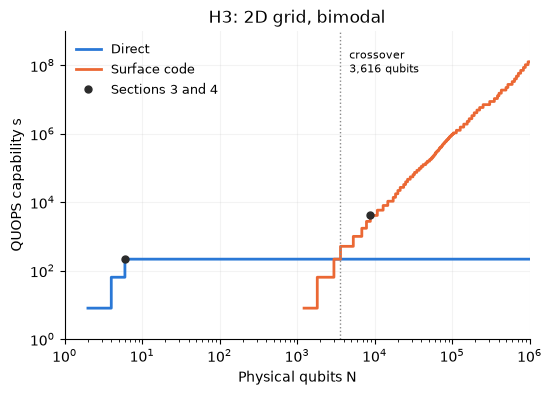

In [9]:
d_rows = direct.sweep(hw, BASELINE)
s_rows = surface.sweep(hw, BASELINE)
N_x = curves.crossover(d_rows, s_rows)

fig, ax = plt.subplots(figsize=(6, 4))
for rows, color, label in ((d_rows, '#2a78d6', 'Direct'), (s_rows, '#eb6834', 'Surface code')):
    y = curves.curve(rows).astype(float)
    y[y == 0] = np.nan
    ax.step(curves.N_GRID, y, where='post', color=color, lw=2, label=label)
ax.plot([6, x['qubits']], [216, 4096], 'o', color='#2b2b2b', ms=5, label='Sections 3 and 4')
ax.axvline(N_x, color='#8a8a8a', lw=1, ls=':')
ax.text(N_x*1.3, 3e8, f'crossover\n{N_x:,.0f} qubits', fontsize=8, va='top')
ax.set(xscale='log', yscale='log', xlim=(1, N_MAX), ylim=(1, 1e9), xlabel='Physical qubits N',
       ylabel='QUOPS capability s', title='H3: 2D grid, bimodal')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.grid(alpha=.15)
ax.legend(frameon=False, fontsize=9, loc='upper left')
plt.show()

The two points are the direct design of section 3, $w = 6$ on 6 qubits, and the surface-code design of section 4, $w = 16$ on 8,768 qubits. The same calculation for the four hardware classes gives the crossovers of the methods note.

In [10]:
for key, hw_k in HARDWARE.items():
    d_k, s_k = direct.sweep(hw_k, BASELINE), surface.sweep(hw_k, BASELINE)
    print(f'{key}: direct s = {curves.capability(d_k, N_MAX):5,}, crossover N = {curves.crossover(d_k, s_k):6,.0f}, '
          f'surface-code s at 1e6 = {surface.capability(N_MAX, hw_k, BASELINE, s_k):.2e}')

H1: direct s =    64, crossover N =  3,928, surface-code s at 1e6 = 5.93e+07


H2: direct s =   144, crossover N =  3,928, surface-code s at 1e6 = 5.93e+07


H3: direct s =   216, crossover N =  3,616, surface-code s at 1e6 = 1.36e+08


H4: direct s = 1,728, crossover N =  7,800, surface-code s at 1e6 = 1.36e+08


## 6. Changing one choice

Each choice in `capability/config.py` can be changed with `vary`. A roomier layout, three patches per logical qubit instead of two, moves the crossover on H3 because the surface code needs more area for the same logical qubits.

In [11]:
roomy = vary(tiles_per_data_patch=3.0)
s_roomy = surface.sweep(hw, roomy)
print(f'H3 crossover: baseline {N_x:,.0f}, roomy layout {curves.crossover(d_rows, s_roomy):,.0f}')

H3 crossover: baseline 3,616, roomy layout 5,936


With cultivation factories only, the output error of the factory caps the capability. A deep-ensemble circuit has about $s/2$ rotations of $n_T$ $T$ gates, so the factory term of the loss alone requires $s \lesssim 1/(n_T P_{\rm factory})$, whatever the number of qubits.

In [12]:
cultivation_only = vary(factories=('cultivation',))
s_cult = surface.sweep(hw, cultivation_only)
z = surface.best_at(N_MAX, hw, cultivation_only, s_cult)
print(f"cultivation only, at most 1e6 qubits: s = {z['s']:.3g} on {z['qubits']:,.0f} qubits, "
      f"n_T = {z['T_per_rotation']}, factory share of the loss {z['loss_magic']:.3f}")
print(f"ceiling 1/(n_T P_factory) = {1/(z['T_per_rotation']*CULTIVATION.error):.3g}")

cultivation only, at most 1e6 qubits: s = 1.06e+07 on 372,976 qubits, n_T = 44, factory share of the loss 0.469
ceiling 1/(n_T P_factory) = 1.14e+07
